<a href="https://colab.research.google.com/github/SayyadRizwan/GAN-based-Oral-Cancer-detection-with-GraphRag/blob/main/ORAL_CANCER_DETECTION_GradCAM_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grad-CAM for the saved EfficientNetB0 oral cancer model

This notebook **loads your existing model from Google Drive**. It does not train, rebuild, or modify the model.

Update `MODEL_PATH` and `IMAGE_PATH` below. The Grad-CAM code uses the EfficientNetB0 `top_conv` layer and avoids constructing a model from the nested backbone's internal input tensor.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model, Model

# EDIT these paths
MODEL_PATH = "/content/drive/MyDrive/Final Year Project/oral_cancer_efficientnetb0.keras"
IMAGE_PATH = "/content/images.jpg"
IMG_SIZE = (224, 224)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

model = load_model(MODEL_PATH, compile=False)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,382,884 (16.72 MB)

 Trainable params: 4,171,101 (15.91 MB)

 Non-trainable params: 211,783 (827.28 KB)

In [13]:
# Load the image exactly as in the original notebook (224 x 224 RGB)
img = image.load_img(IMAGE_PATH, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
input_array = np.expand_dims(img_array, axis=0).astype("float32")

# Original model has one sigmoid output: >= 0.5 means OSCC
score = float(model(input_array, training=False).numpy().reshape(-1)[0])
predicted_label = "OSCC" if score >= 0.5 else "Normal"
confidence = score if score >= 0.5 else 1.0 - score

print(f"Prediction: {predicted_label}")
print(f"Confidence: {confidence * 100:.2f}%")

Prediction: OSCC
Confidence: 73.56%


## Grad-CAM

The key fix is **not** to create `Model(inputs=model.inputs, outputs=backbone.input)`. `backbone.input` belongs to the nested model's own graph and can cause the `KeyError` you saw. Instead, call a feature model whose input is the backbone's own input directly. For this model, EfficientNet's preprocessing function is a no-op in standard TensorFlow/Keras EfficientNet implementations; the original augmentation layer is inactive during inference.

Backbone: efficientnetb0
Grad-CAM convolution layer: top_conv


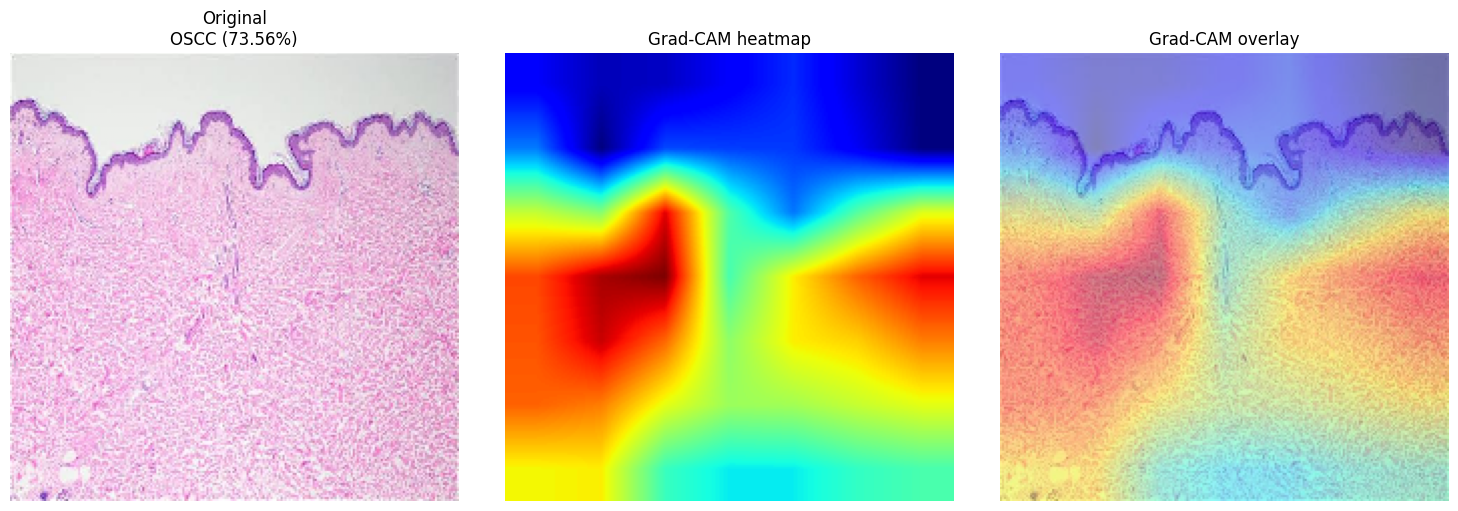

In [14]:
# Find the saved EfficientNetB0 nested model
backbone = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model) and "efficientnet" in layer.name.lower():
        backbone = layer
        break

if backbone is None:
    print("Top-level model layers:", [(i, layer.name, type(layer).__name__) for i, layer in enumerate(model.layers)])
    raise ValueError(
        "Could not automatically find the nested EfficientNet backbone. "
        "Check model.summary() and set `backbone` to the correct nested model."
    )

last_conv_layer_name = "top_conv"
try:
    conv_layer = backbone.get_layer(last_conv_layer_name)
except ValueError as exc:
    raise ValueError(
        f"Layer '{last_conv_layer_name}' was not found inside {backbone.name}. "
        f"Check backbone.summary() for the exact convolution layer name."
    ) from exc

print("Backbone:", backbone.name)
print("Grad-CAM convolution layer:", conv_layer.name)

# Both outputs are from the backbone's own graph.
feature_model = Model(
    inputs=backbone.inputs,
    outputs=[conv_layer.output, backbone.output],
    name="gradcam_feature_model"
)

# Reuse the already-trained classification-head layers following the backbone.
try:
    backbone_index = next(i for i, layer in enumerate(model.layers) if layer is backbone)
except StopIteration:
    raise ValueError("The detected backbone is not a top-level layer of the saved model.")

head_layers = model.layers[backbone_index + 1:]

def classify_from_backbone_features(features):
    x = features
    for layer in head_layers:
        # Inference mode ensures Dropout is inactive and BatchNorm uses saved statistics.
        try:
            x = layer(x, training=False)
        except TypeError:
            x = layer(x)
    return x

# IMPORTANT: Feed the image directly to the nested backbone feature model.
# Do not use Model(inputs=model.inputs, outputs=backbone.input).
with tf.GradientTape() as tape:
    conv_outputs, backbone_features = feature_model(input_array, training=False)
    predictions = classify_from_backbone_features(backbone_features)
    sigmoid_score = predictions[:, 0]

    # Explain the predicted class score. For Normal, use 1 - sigmoid score.
    if score >= 0.5:
        target_score = sigmoid_score
    else:
        target_score = 1.0 - sigmoid_score

grads = tape.gradient(target_score, conv_outputs)

if grads is None:
    raise RuntimeError(
        "Gradients are None. Please share model.summary() and the full error; "
        "the saved model may have a different nested structure."
    )

# Global-average-pool gradients into channel weights, then form the heatmap.
weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + tf.keras.backend.epsilon())
heatmap = heatmap[0].numpy()

# Resize heatmap and overlay it on the original image
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis], IMG_SIZE, method="bilinear"
).numpy().squeeze()

original = np.asarray(img).astype(np.float32) / 255.0
colored_heatmap = plt.get_cmap("jet")(heatmap_resized)[..., :3]
overlay = np.clip(0.55 * original + 0.45 * colored_heatmap, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(original)
axes[0].set_title(f"Original\n{predicted_label} ({confidence * 100:.2f}%)")
axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM heatmap")
axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
import cv2
import numpy as np

def create_gradcam_overlay(
    original_image,
    heatmap,
    alpha=0.35
):
    """
    original_image: RGB image, uint8, shape (H, W, 3)
    heatmap: normalized Grad-CAM map, shape (h, w), values [0, 1]
    """

    h, w = original_image.shape[:2]

    heatmap = cv2.resize(
        heatmap.astype(np.float32),
        (w, h)
    )

    heatmap = np.clip(heatmap, 0, 1)

    heatmap_uint8 = np.uint8(255 * heatmap)

    colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    colored = cv2.cvtColor(
        colored,
        cv2.COLOR_BGR2RGB
    )

    overlay = (
        (1 - alpha) * original_image.astype(np.float32)
        + alpha * colored.astype(np.float32)
    )

    return np.clip(overlay, 0, 255).astype(np.uint8)

Loaded model: functional_1
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Backbone: efficientnetb0
Grad-CAM layer: top_conv


100%|██████████| 2.93G/2.93G [00:36<00:00, 86.0MB/s]

Extracting files...



Dataset downloaded: /root/.cache/kagglehub/datasets/ashenafifasilkebede/dataset/versions/1
Total images found: 5192
train/OSCC: 2511
train/Normal: 2435
test/OSCC: 95
val/OSCC: 92
test/Normal: 31
val/Normal: 28

Evaluation source: Existing Kaggle test folder
Selected images: 50
Label mapping: Normal=0, OSCC=1
1/50 | Normal | Deletion AUC=0.6403 | Insertion AUC=0.8304
2/50 | Normal | Deletion AUC=0.3844 | Insertion AUC=0.6806
3/50 | Normal | Deletion AUC=0.3759 | Insertion AUC=0.6688
4/50 | Normal | Deletion AUC=0.4053 | Insertion AUC=0.9263
5/50 | Normal | Deletion AUC=0.5539 | Insertion AUC=0.7262
6/50 | Normal | Deletion AUC=0.5405 | Insertion AUC=0.9367
7/50 | Normal | Deletion AUC=0.2354 | Insertion AUC=0.8441
8/50 | OSCC | Deletion AUC=0.8199 | Insertion AUC=0.8810
9/50 | Normal | Deletion AUC=0.4607 | Insertion AUC=0.9536
10/50 | OSCC | Deletion AUC=0.8046 | Insertion AUC=0.9222
11/50 | Normal | Deletion AUC=0.4783 | Insertion AUC=0.6198
12/50 | Normal | Deletion AUC=0.4356 | Ins

,count,mean,std,median
deletion_auc,50.0,0.5309,0.1916,0.5472
insertion_auc,50.0,0.8245,0.1391,0.8885
random_deletion_auc,50.0,0.5709,0.2230,0.5444
random_insertion_auc,50.0,0.5826,0.2343,0.5826
heatmap_stability_cosine,50.0,0.9888,0.0117,0.9943
prediction_consistency,50.0,0.9667,0.1684,1.0000


Accuracy on selected images: 0.76

Saved: gradcam_evaluation.csv
Saved: gradcam_summary.csv


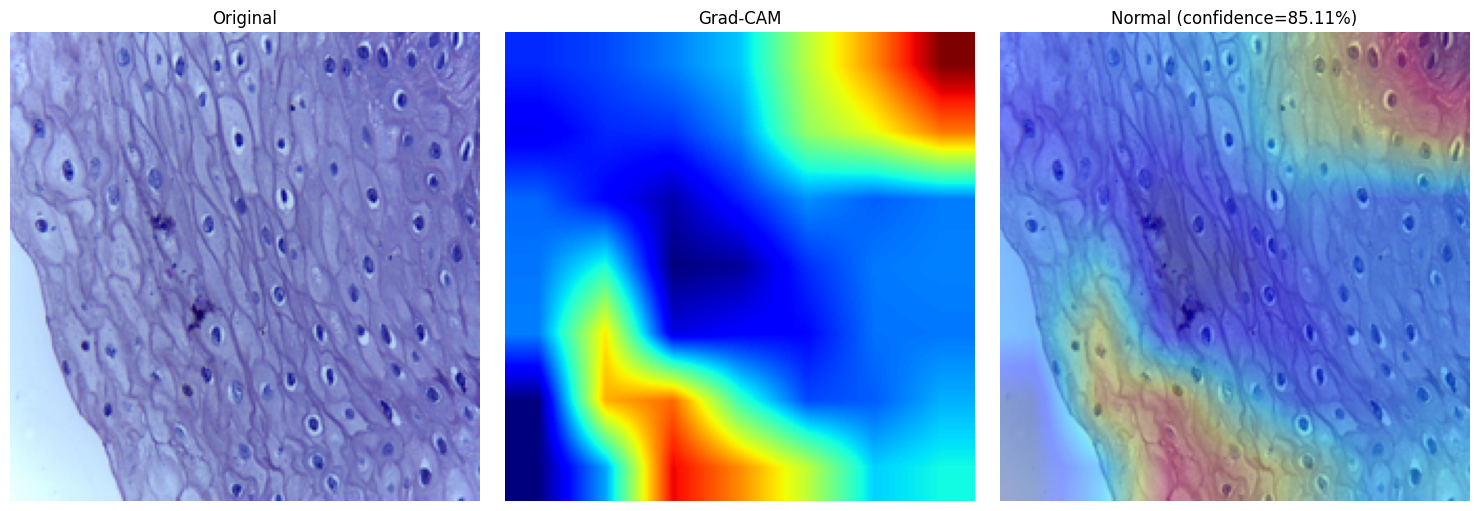

In [18]:

# ================================================================
# ONE-CELL GRAD-CAM EVALUATION
# KaggleHub + Saved EfficientNetB0 + Deletion/Insertion + Stability
# ================================================================

!pip -q install kagglehub

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from collections import Counter

# ------------------------ SETTINGS --------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/Final Year Project/"
    "oral_cancer_efficientnetb0.keras"
)
DATASET_ID = "ashenafifasilkebede/dataset"
IMG_SIZE = (224, 224)
MAX_IMAGES = 50       # Set None to evaluate all selected images
N_STEPS = 10
N_STABILITY_TRIALS = 3
SEED = 42

# According to your existing notebook, sigmoid >= 0.5 means OSCC.
# The dataset folders must contain names identifying OSCC and Normal.

np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------ LOAD SAVED MODEL ------------------------

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}\n"
        "Check that Google Drive is mounted and MODEL_PATH is correct."
    )

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("Loaded model:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

if model.output_shape[-1] != 1:
    raise ValueError("Expected the saved one-output sigmoid classifier.")

# Find the nested EfficientNetB0 backbone.
backbone = next(
    (
        layer for layer in model.layers
        if isinstance(layer, tf.keras.Model)
        and "efficientnet" in layer.name.lower()
    ),
    None
)

if backbone is None:
    raise ValueError(
        "Could not find the nested EfficientNet backbone. "
        "Inspect model.summary() before continuing."
    )

conv_layer = backbone.get_layer("top_conv")

backbone_index = next(
    i for i, layer in enumerate(model.layers)
    if layer is backbone
)
head_layers = model.layers[backbone_index + 1:]

feature_model = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[conv_layer.output, backbone.output]
)

def classify_from_features(features):
    x = features
    for layer in head_layers:
        try:
            x = layer(x, training=False)
        except TypeError:
            x = layer(x)
    return x

print("Backbone:", backbone.name)
print("Grad-CAM layer:", conv_layer.name)

# ------------------------ DOWNLOAD DATASET ------------------------

dataset_path = Path(
    kagglehub.dataset_download(DATASET_ID)
)

print("\nDataset downloaded:", dataset_path)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

if not image_paths:
    raise ValueError("No supported image files found in Kaggle dataset.")

print("Total images found:", len(image_paths))

# Print structure so folder assumptions are visible.
for folder, count in Counter(
    str(p.parent.relative_to(dataset_path))
    for p in image_paths
).most_common(25):
    print(f"{folder}: {count}")

# ------------------------ IDENTIFY CLASS LABELS -------------------

split_names = {
    "train", "training", "test", "testing",
    "val", "valid", "validation"
}

def infer_class(path):
    parts = path.relative_to(dataset_path).parts

    # Handles split/class/image.jpg.
    for i, part in enumerate(parts[:-1]):
        if part.lower() in split_names and i + 1 < len(parts) - 1:
            return parts[i + 1]

    # Handles class/image.jpg.
    if len(parts) >= 2:
        return parts[-2]

    return None

records = [
    (p, infer_class(p))
    for p in image_paths
]
records = [(p, c) for p, c in records if c is not None]

def normalize_label(name):
    s = name.lower().replace("_", "").replace("-", "").replace(" ", "")

    if "oscc" in s or "cancer" in s or "carcinoma" in s:
        return 1
    if "normal" in s or "benign" in s or "healthy" in s:
        return 0

    return None

records = [
    (p, c, normalize_label(c))
    for p, c in records
]
records = [(p, c, y) for p, c, y in records if y is not None]

if not records:
    raise ValueError(
        "Could not identify OSCC and Normal labels from folder names. "
        "Inspect the printed folder structure and adjust normalize_label()."
    )

# Prefer a dataset test split if it exists.
test_records = [
    (p, c, y) for p, c, y in records
    if any(
        part.lower() in {"test", "testing"}
        for part in p.relative_to(dataset_path).parts[:-1]
    )
]

if test_records:
    records = test_records
    split_status = "Existing Kaggle test folder"
else:
    # Explicitly exploratory if no held-out split exists.
    split_status = (
        "No test folder found; all recognized images used. "
        "NOT an independent test evaluation."
    )

if MAX_IMAGES is not None:
    records = records[:MAX_IMAGES]

if not records:
    raise ValueError("No eligible labeled images remain.")

print("\nEvaluation source:", split_status)
print("Selected images:", len(records))
print("Label mapping: Normal=0, OSCC=1")

# ------------------------ IMAGE LOADING ---------------------------

def load_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(IMG_SIZE)
        return np.asarray(im, dtype=np.float32)

# Matches the saved notebook: raw RGB pixels [0, 255].
# Its preprocessing/augmentation layer is inside the saved model.

def predict_positive(batch):
    outputs = model(
        tf.convert_to_tensor(batch, dtype=tf.float32),
        training=False
    ).numpy().reshape(-1)

    # Saved model has a sigmoid output.
    if np.any(outputs < 0) or np.any(outputs > 1):
        outputs = tf.sigmoid(outputs).numpy()

    return np.clip(outputs, 0, 1)

# ------------------------ GRAD-CAM --------------------------------

def generate_gradcam(img, target_class):
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, features = feature_model(x, training=False)
        prediction = classify_from_features(features)[:, 0]

        target_score = (
            prediction if target_class == 1
            else 1.0 - prediction
        )

    grads = tape.gradient(target_score, conv_outputs)

    if grads is None:
        raise RuntimeError("Grad-CAM gradients are None.")

    weights = tf.reduce_mean(
        grads, axis=(1, 2), keepdims=True
    )

    cam = tf.reduce_sum(
        weights * conv_outputs, axis=-1
    )
    cam = tf.nn.relu(cam)

    cam = tf.image.resize(
        cam[..., None], IMG_SIZE
    )[0, ..., 0].numpy()

    cam = np.nan_to_num(cam)
    return (cam / max(float(cam.max()), 1e-8)).astype(np.float32)

# ------------------------ DELETION / INSERTION --------------------

def evaluate_faithfulness(img, cam, target_class):
    h, w, channels = img.shape
    pixels = img.reshape(-1, channels)
    heat = cam.reshape(-1)
    total = len(heat)

    # Mean RGB replacement baseline.
    baseline = np.broadcast_to(
        img.mean(axis=(0, 1)),
        img.shape
    ).reshape(-1, channels).copy()

    fractions = np.linspace(0, 1, N_STEPS + 1)

    def score_for_class(batch):
        p = predict_positive(batch)
        return p if target_class == 1 else 1 - p

    def get_auc(order):
        deletion_scores, insertion_scores = [], []

        for fraction in fractions:
            k = int(round(fraction * total))
            deleted = pixels.copy()
            inserted = baseline.copy()

            if k > 0:
                idx = order[:k]
                deleted[idx] = baseline[idx]
                inserted[idx] = pixels[idx]

            batch = np.stack([
                deleted.reshape(h, w, channels),
                inserted.reshape(h, w, channels)
            ])

            scores = score_for_class(batch)
            deletion_scores.append(float(scores[0]))
            insertion_scores.append(float(scores[1]))

        return (
            float(np.trapezoid(deletion_scores, fractions)),
            float(np.trapezoid(insertion_scores, fractions)),
            deletion_scores[0] - deletion_scores[-1],
            insertion_scores[-1] - insertion_scores[0]
        )

    cam_order = np.argsort(heat)[::-1]
    random_order = rng.permutation(total)

    d_auc, i_auc, d_drop, i_gain = get_auc(cam_order)
    rd_auc, ri_auc, _, _ = get_auc(random_order)

    return {
        "deletion_auc": d_auc,
        "insertion_auc": i_auc,
        "random_deletion_auc": rd_auc,
        "random_insertion_auc": ri_auc,
        "target_score_drop": d_drop,
        "target_score_gain": i_gain
    }

# ------------------------ STABILITY --------------------------------

def evaluate_stability(img, cam):
    original_prediction = int(predict_positive(img[None])[0] >= 0.5)

    similarities = []
    consistency = []

    for _ in range(N_STABILITY_TRIALS):
        # Mild brightness and pixel-noise perturbation.
        perturbed = img * rng.uniform(0.98, 1.02)
        perturbed += rng.normal(
            0, 1.0, img.shape
        ).astype(np.float32)
        perturbed = np.clip(perturbed, 0, 255)

        pred = int(predict_positive(perturbed[None])[0] >= 0.5)
        consistency.append(float(pred == original_prediction))

        # Keep the original predicted class fixed.
        target_class = original_prediction
        new_cam = generate_gradcam(perturbed, target_class)

        a, b = cam.ravel(), new_cam.ravel()
        denominator = np.linalg.norm(a) * np.linalg.norm(b)

        if denominator > 1e-12:
            similarities.append(float(np.dot(a, b) / denominator))

    return {
        "heatmap_stability_cosine": (
            float(np.mean(similarities)) if similarities else np.nan
        ),
        "prediction_consistency": float(np.mean(consistency))
    }

# ------------------------ RUN EVALUATION ---------------------------

results = []
example = None

for i, (path, folder_label, true_label) in enumerate(records, start=1):
    img = load_image(path)

    positive_prob = float(predict_positive(img[None])[0])
    pred_label = int(positive_prob >= 0.5)

    cam = generate_gradcam(img, pred_label)

    row = {
        "image_path": str(path),
        "dataset_folder_label": folder_label,
        "true_class": "OSCC" if true_label == 1 else "Normal",
        "predicted_class": "OSCC" if pred_label == 1 else "Normal",
        "positive_class_probability": positive_prob,
        "predicted_class_confidence": (
            positive_prob if pred_label == 1 else 1 - positive_prob
        ),
        "prediction_correct": int(pred_label == true_label),
        "evaluation_source": split_status
    }

    row.update(evaluate_faithfulness(img, cam, pred_label))
    row.update(evaluate_stability(img, cam))

    results.append(row)

    if example is None:
        example = (img.copy(), cam.copy(), row.copy())

    print(
        f"{i}/{len(records)} | {row['predicted_class']} | "
        f"Deletion AUC={row['deletion_auc']:.4f} | "
        f"Insertion AUC={row['insertion_auc']:.4f}"
    )

# ------------------------ EXPORT CSV --------------------------------

df = pd.DataFrame(results)
df.to_csv("gradcam_evaluation.csv", index=False)

metric_cols = [
    "deletion_auc", "insertion_auc",
    "random_deletion_auc", "random_insertion_auc",
    "heatmap_stability_cosine", "prediction_consistency"
]

summary = df[metric_cols].agg(
    ["count", "mean", "std", "median"]
).T

summary.to_csv("gradcam_summary.csv")

print("\n========== GRAD-CAM EVALUATION SUMMARY ==========")
display(summary.round(4))

print(
    "Accuracy on selected images:",
    round(df["prediction_correct"].mean(), 4)
)
print("\nSaved: gradcam_evaluation.csv")
print("Saved: gradcam_summary.csv")

# ------------------------ VISUALIZE EXAMPLE -------------------------

img, cam, row = example
colored = plt.get_cmap("jet")(cam)[..., :3]
overlay = np.clip(
    0.65 * img / 255.0 + 0.35 * colored, 0, 1
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img / 255.0)
axes[0].set_title("Original")

axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM")

axes[2].imshow(overlay)
axes[2].set_title(
    f"{row['predicted_class']} "
    f"(confidence={row['predicted_class_confidence']:.2%})"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
